# Chapter 37: The Foundations of Modern Physics

Around 1900, a handful of experiments showed that matter is made of
smaller charged pieces — and that classical physics could not explain
how those pieces hold together. This notebook works through them in
the order the chapter does.

| Section | Topic | Key result |
|---|---|---|
| 1 | Matter and light: spectra | hydrogen emits only $\lambda = \dfrac{91.18\ \text{nm}}{1/m^2 - 1/n^2}$ |
| 2 | Cathode rays and X rays | X rays diffract from crystals: $2d\sin\theta = m\lambda$ |
| 3 | Discovery of the electron | crossed fields give $v = E/B$ and then $e/m$ |
| 4 | The fundamental unit of charge | Millikan: every charge is a whole multiple of $e$ |
| 5 | Discovery of the nucleus | Rutherford scattering: $b = \tfrac{d}{2}\cot\tfrac{\theta}{2}$ |
| 6 | Into the nucleus | $R \approx 1.2\ \text{fm}\,A^{1/3}$; nuclear density is constant |
| 7 | Classical physics at the limit | a classical atom would collapse in about $10^{-11}$ s |

The section list follows the chapter's topics as usually taught; check
it against your book's learning objectives. Constants are CODATA values
from `scipy.constants`. Every worked number is asserted.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.constants import c, e, epsilon_0, g, m_e, m_p, physical_constants

k = 1 / (4 * np.pi * epsilon_0)                       # Coulomb constant, N m^2 / C^2
ke2_MeV_fm = k * e**2 / (e * 1e6) / 1e-15             # k e^2 in MeV fm (about 1.44)
print(f"k e^2 = {ke2_MeV_fm:.4f} MeV fm")
print(f"e / m_e = {e / m_e:.4e} C/kg")

k e^2 = 1.4400 MeV fm
e / m_e = 1.7588e+11 C/kg


# 1 — Matter and light: discrete spectra

Hot solids glow with a **continuous** spectrum. A hot, low-density gas
does not: it emits light only at a few sharp wavelengths, different for
each element, and absorbs at exactly the same wavelengths. Those lines
are a fingerprint of the atom.

For hydrogen, Balmer (1885) and Rydberg found that every line fits

$$\lambda = \frac{91.18\ \text{nm}}{\dfrac{1}{m^2} - \dfrac{1}{n^2}}, \qquad n > m \text{ whole numbers}.$$

$m = 2$ gives the visible **Balmer series**. Nobody could say *why* this
formula worked — that is the puzzle Chapter 38 answers. The 91.18 nm is
$1/R_H$, the inverse of the Rydberg constant for hydrogen.

In [2]:
R_inf = physical_constants["Rydberg constant"][0]           # 1/m
R_H = R_inf / (1 + m_e / m_p)                                # corrected for the proton's finite mass
lambda_0 = 1 / R_H
print(f"1 / R_H = {lambda_0 * 1e9:.2f} nm")


def hydrogen_line_nm(m, n):
    return lambda_0 / (1 / m**2 - 1 / n**2) * 1e9


names = {3: "H-alpha (red)", 4: "H-beta (blue-green)", 5: "H-gamma (violet)", 6: "H-delta (violet)"}
print("\nBalmer series (m = 2), vacuum wavelengths:")
for n in range(3, 8):
    print(f"  n = {n}:  {hydrogen_line_nm(2, n):7.1f} nm   {names.get(n, '')}")
print(f"  series limit (n -> infinity): {4 * lambda_0 * 1e9:.1f} nm")
assert abs(hydrogen_line_nm(2, 3) - 656.5) < 0.1 and abs(hydrogen_line_nm(2, 4) - 486.3) < 0.1

1 / R_H = 91.18 nm

Balmer series (m = 2), vacuum wavelengths:
  n = 3:    656.5 nm   H-alpha (red)
  n = 4:    486.3 nm   H-beta (blue-green)
  n = 5:    434.2 nm   H-gamma (violet)
  n = 6:    410.3 nm   H-delta (violet)
  n = 7:    397.1 nm   
  series limit (n -> infinity): 364.7 nm


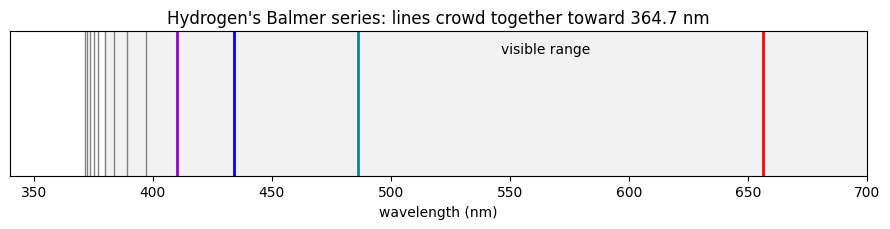

In [3]:
colors = {3: "red", 4: "darkcyan", 5: "blue", 6: "darkviolet"}
fig, ax = plt.subplots(figsize=(9, 2.4))
for n in range(3, 16):
    wavelength = hydrogen_line_nm(2, n)
    ax.axvline(wavelength, color=colors.get(n, "0.5"), lw=2 if n in colors else 1)
ax.axvspan(380, 750, color="0.95", zorder=0)
ax.text(565, 0.85, "visible range", ha="center", transform=ax.get_xaxis_transform())
ax.set_xlim(340, 700); ax.set_yticks([]); ax.set_xlabel("wavelength (nm)")
ax.set_title("Hydrogen's Balmer series: lines crowd together toward 364.7 nm")
plt.tight_layout(); plt.show()

# 2 — Cathode rays and X rays

A **cathode ray** is the glowing beam inside an evacuated tube with a
high voltage across it. It travels in straight lines, is bent by
magnetic and electric fields, and carries negative charge — so it is a
stream of particles, not light. Section 3 finds out what they are.

When cathode rays slam into metal they produce **X rays**: penetrating
radiation that is *not* bent by fields. Proof that X rays are waves
came from crystals. The atoms in a crystal sit in planes a distance $d$
apart; waves reflected from successive planes add up only when the
extra path $2d\sin\theta$ is a whole number of wavelengths:

$$2d\sin\theta_m = m\lambda \qquad \text{(Bragg condition)}.$$

**Example.** Copper X rays ($\lambda = 0.154$ nm) on rock salt, whose
planes are $d = 0.282$ nm apart.

In [4]:
d_nacl, lambda_xray = 0.282e-9, 0.154e-9
print("order m   angle theta")
for order in (1, 2, 3):
    ratio = order * lambda_xray / (2 * d_nacl)
    if ratio <= 1:
        print(f"   {order}      {np.degrees(np.arcsin(ratio)):.1f} deg")
    else:
        print(f"   {order}      none: m*lambda/2d = {ratio:.2f} > 1")
assert abs(np.degrees(np.arcsin(lambda_xray / (2 * d_nacl))) - 15.8) < 0.1

order m   angle theta
   1      15.8 deg
   2      33.1 deg
   3      55.0 deg


Only a few orders exist, because $\sin\theta$ cannot exceed 1. The
same equation run backwards — measure $\theta$, know $\lambda$ — gives
the spacing of atoms in a crystal, which is how crystal structures
(eventually including DNA's) are determined.

# 3 — The discovery of the electron: Thomson's $e/m$

J. J. Thomson (1897) measured the charge-to-mass ratio of cathode-ray
particles with two steps.

**Step 1 — speed from crossed fields.** An electric field $E$ pushes
the particle one way; a magnetic field $B$ pushes it the other way with
force $qvB$. When the beam goes straight, the forces balance:
$qE = qvB$, so $v = E/B$.

**Step 2 — deflection with $E$ alone.** Turn off $B$. Inside plates of
length $L$ the particle feels a constant sideways acceleration
$a = qE/m$ for a time $L/v$, so it leaves deflected by

$$y = \frac{1}{2}\frac{qE}{m}\left(\frac{L}{v}\right)^2
\quad\Longrightarrow\quad \frac{q}{m} = \frac{2yv^2}{EL^2} = \frac{2yE}{B^2L^2}.$$

In [5]:
q_s, m_s, E_s, B_s, L_s, x_s = sp.symbols("q m E B L x", positive=True)
v_s = E_s / B_s                                          # step 1: undeflected speed
y_path = sp.Rational(1, 2) * (q_s * E_s / m_s) * (x_s / v_s)**2   # step 2: parabola inside the plates
y_exit = y_path.subs(x_s, L_s)
q_over_m = sp.solve(sp.Eq(sp.Symbol("y", positive=True), y_exit), q_s)[0] / m_s
print("deflection inside plates  y(x) =", y_path)
print("solve for q/m             q/m  =", sp.simplify(q_over_m))

# a simulated measurement with real electron properties
E_field, B_field, L_plates = 2.0e4, 1.0e-3, 0.05        # V/m, T, m
speed = E_field / B_field
y_measured = 0.5 * (e / m_e) * E_field * (L_plates / speed)**2
e_over_m = 2 * y_measured * E_field / (B_field**2 * L_plates**2)
print(f"\nE = {E_field:.1e} V/m, B = {B_field * 1e3:.1f} mT  ->  v = {speed:.2e} m/s")
print(f"deflection after {L_plates * 100:.0f} cm of plate: y = {y_measured * 1e3:.1f} mm")
print(f"recovered e/m = {e_over_m:.4e} C/kg   (proton: {e / m_p:.3e}, about 1836 times smaller)")
assert abs(e_over_m / (e / m_e) - 1) < 1e-12 and abs(y_measured * 1e3 - 11.0) < 0.1

deflection inside plates  y(x) = B**2*q*x**2/(2*E*m)
solve for q/m             q/m  = 2*E*y/(B**2*L**2)

E = 2.0e+04 V/m, B = 1.0 mT  ->  v = 2.00e+07 m/s
deflection after 5 cm of plate: y = 11.0 mm
recovered e/m = 1.7588e+11 C/kg   (proton: 9.579e+07, about 1836 times smaller)


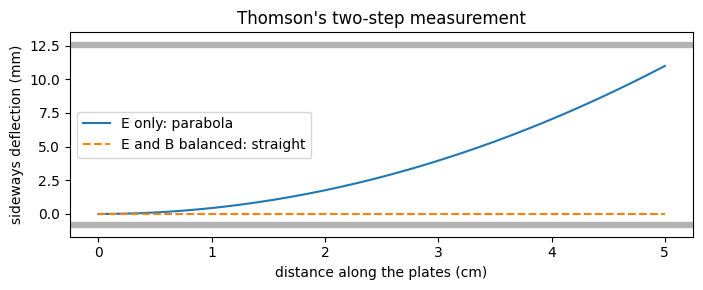

In [6]:
xs = np.linspace(0, L_plates, 200)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(xs * 100, 0.5 * (e / m_e) * E_field * (xs / speed)**2 * 1000, label="E only: parabola")
ax.plot(xs * 100, np.zeros_like(xs), "--", label="E and B balanced: straight")
ax.axhspan(-1, -0.6, color="0.7"); ax.axhspan(12.4, 12.8, color="0.7")
ax.set_xlabel("distance along the plates (cm)"); ax.set_ylabel("sideways deflection (mm)")
ax.set_title("Thomson's two-step measurement"); ax.legend(loc="center left")
plt.tight_layout(); plt.show()

Thomson's $e/m$ was about a thousand times larger than hydrogen
ions' — and the same for every cathode metal and gas. Either the
particle carried a huge charge or it had a tiny mass. Millikan settled
which.

# 4 — The fundamental unit of charge: Millikan's oil drops

Millikan sprayed tiny oil drops between two horizontal plates and
watched them through a microscope.

1. **Plates off: measure the drop's size.** The drop falls at a steady
   (terminal) speed $v$ where air drag $6\pi\eta r v$ (Stokes' law)
   balances weight $\tfrac43\pi r^3\rho g$. So
   $r = \sqrt{9\eta v / (2\rho g)}$, and from $r$ the mass.
2. **Plates on: measure the drop's charge.** Adjust the voltage $V$
   until the drop hangs still: $qV/d = mg$, so $q = mgd/V$.

Every charge came out a whole-number multiple of one value, $e$.

Below is a **simulated** version of the experiment with realistic
values (oil density 860 kg/m³, air viscosity 1.83 × 10⁻⁵ Pa·s, plates
6 mm apart), 40 drops carrying 1 to 5 extra electrons, and 2 % noise on
the fall speed and 0.5 % on the voltage. The analysis does not know the
answer.

In [7]:
rng = np.random.default_rng(37)
eta, rho_oil, gap = 1.83e-5, 860.0, 6.0e-3
n_drops = 40

# --- the simulated experiment (truth hidden from the analysis below) ---
true_radius = rng.uniform(0.6e-6, 1.2e-6, n_drops)
true_n = rng.integers(1, 6, n_drops)
true_mass = 4 / 3 * np.pi * true_radius**3 * rho_oil
fall_speed = 2 * rho_oil * g * true_radius**2 / (9 * eta) * (1 + 0.02 * rng.normal(size=n_drops))
hold_voltage = true_mass * g * gap / (true_n * e) * (1 + 0.005 * rng.normal(size=n_drops))

# --- the analysis: only fall_speed and hold_voltage are used ---
radius = np.sqrt(9 * eta * fall_speed / (2 * rho_oil * g))
mass = 4 / 3 * np.pi * radius**3 * rho_oil
charge = mass * g * gap / hold_voltage
print(f"typical drop: radius {np.median(radius) * 1e6:.2f} um, falls {np.median(fall_speed) * 1e3:.3f} mm/s,"
      f" held by {np.median(hold_voltage):.0f} V")
print("first five charges (1e-19 C):", np.round(charge[:5] / 1e-19, 2))

typical drop: radius 0.83 um, falls 0.070 mm/s, held by 265 V
first five charges (1e-19 C): [1.54 7.78 6.38 5.05 8.19]


**Finding $e$ without knowing it.** If every charge is a whole multiple
of some unit $u$, then every $q/u$ is (close to) a whole number, and
the complex numbers $e^{2\pi i q/u}$ all point the same way. Their
average length, the *coherence*

$$S(u) = \left|\frac{1}{N}\sum_i e^{2\pi i\, q_i/u}\right| ,$$

is near 1 at the true unit — and also at $u/2$, $u/3, \dots$, since
those divide every charge too. Measurement noise keeps the peaks below
1, so the rule used is: the fundamental charge is the **largest** $u$
whose coherence peak is at least half as tall as the tallest peak. A
least-squares fit then refines it.

largest highly coherent unit: 1.618e-19 C
least-squares fit:  e = (1.6037 +/- 0.0073) x 1e-19 C
accepted value:     e =  1.6022 x 1e-19 C
multiples found match the hidden truth for 40 of 40 drops


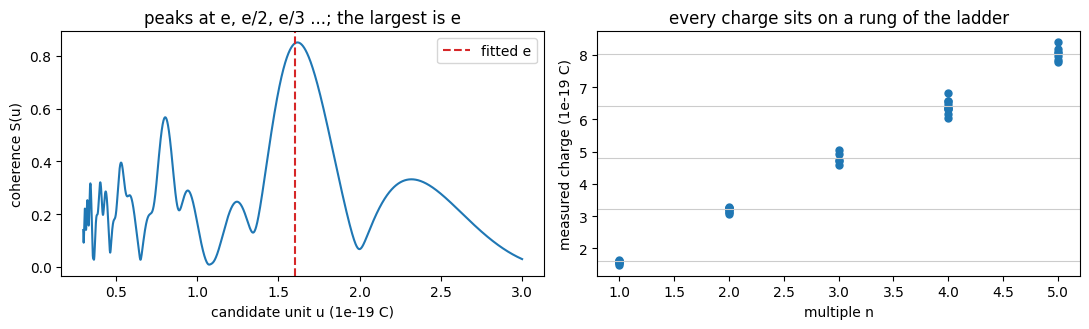

In [8]:
from scipy.signal import find_peaks

candidates = np.linspace(0.3e-19, 3.0e-19, 6000)
coherence = np.abs(np.exp(2j * np.pi * charge[None, :] / candidates[:, None]).mean(axis=1))
peaks, _ = find_peaks(coherence)
strong = peaks[coherence[peaks] > 0.5 * coherence.max()]   # peaks at least half as tall as the tallest
rough = candidates[strong].max()                          # the largest unit everything is a multiple of
multiples = np.round(charge / rough)
e_fit = np.sum(charge * multiples) / np.sum(multiples**2)   # least squares for q_i = n_i e
residual = charge - multiples * e_fit
e_sigma = np.sqrt(np.sum(residual**2) / (n_drops - 1) / np.sum(multiples**2))

print(f"largest highly coherent unit: {rough:.3e} C")
print(f"least-squares fit:  e = ({e_fit / 1e-19:.4f} +/- {e_sigma / 1e-19:.4f}) x 1e-19 C")
print(f"accepted value:     e =  {e / 1e-19:.4f} x 1e-19 C")
print(f"multiples found match the hidden truth for {np.sum(multiples == true_n)} of {n_drops} drops")
assert np.all(multiples == true_n) and abs(e_fit / e - 1) < 0.01

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(candidates / 1e-19, coherence)
axes[0].axvline(e_fit / 1e-19, color="C3", ls="--", label="fitted e")
axes[0].set_xlabel("candidate unit u (1e-19 C)"); axes[0].set_ylabel("coherence S(u)")
axes[0].set_title("peaks at e, e/2, e/3 ...; the largest is e"); axes[0].legend()
axes[1].plot(multiples, charge / 1e-19, "o", ms=5)
for n in range(1, 6):
    axes[1].axhline(n * e_fit / 1e-19, color="0.8", lw=0.8)
axes[1].set_xlabel("multiple n"); axes[1].set_ylabel("measured charge (1e-19 C)")
axes[1].set_title("every charge sits on a rung of the ladder")
plt.tight_layout(); plt.show()

Combining Millikan's $e$ with Thomson's $e/m$ gives the electron's
mass:

In [9]:
electron_mass = e_fit / e_over_m
print(f"m = e / (e/m) = {electron_mass:.3e} kg   (accepted {m_e:.3e} kg)")
print(f"proton mass / electron mass = {m_p / m_e:.1f}")
assert abs(electron_mass / m_e - 1) < 0.01

m = e / (e/m) = 9.118e-31 kg   (accepted 9.109e-31 kg)
proton mass / electron mass = 1836.2


# 5 — The discovery of the nucleus: Rutherford scattering

Thomson's picture of the atom was a "plum pudding": electrons embedded
in a diffuse sphere of positive charge. Geiger and Marsden fired alpha
particles (charge $+2e$, a few MeV) at thin gold foil. Most went
straight through — but a few bounced almost straight back. A diffuse
sphere cannot do that. Rutherford (1911) concluded that the positive
charge and nearly all the mass sit in a tiny **nucleus**.

**Closest approach.** A head-on alpha stops where its kinetic energy
$K$ has all become electric potential energy:

$$d = \frac{k\,(2e)(Ze)}{K} .$$

**Scattering angle.** An alpha aimed a sideways distance $b$ (the
*impact parameter*) from the nucleus follows a hyperbola and is
deflected by $\theta$, where

$$b = \frac{d}{2}\cot\frac{\theta}{2} .$$

Small $b$ means a large angle. Backscattering ($\theta > 90^\circ$)
needs $b < d/2$ — a target area that is tiny compared with the atom.

5.0 MeV alpha on gold: distance of closest approach d = 45.5 fm
a gold atom (radius about 0.14 nm = 140,000 fm) is roughly 3,100 times larger

  b/d    simulated angle   formula 2*arctan(d/2b)
  0.25      126.86 deg         126.87 deg
  0.50       89.99 deg          90.00 deg
  1.00       53.12 deg          53.13 deg
  2.00       28.07 deg          28.07 deg
  4.00       14.25 deg          14.25 deg


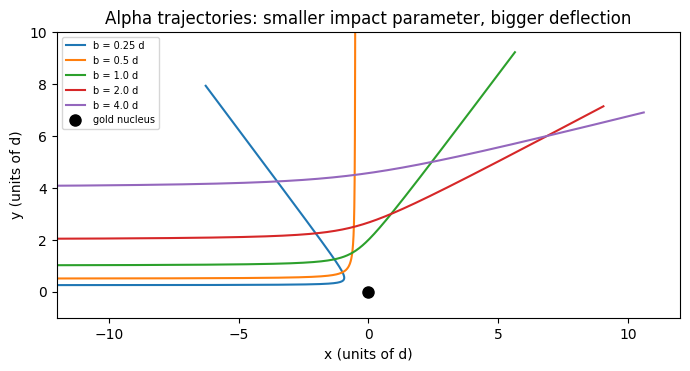

In [10]:
Z_gold, K_alpha = 79, 5.0                                # MeV
d_fm = ke2_MeV_fm * 2 * Z_gold / K_alpha
print(f"5.0 MeV alpha on gold: distance of closest approach d = {d_fm:.1f} fm")
print(f"a gold atom (radius about 0.14 nm = 140,000 fm) is roughly {round(140_000 / d_fm, -2):,.0f} times larger")
assert abs(d_fm - 45.5) < 0.1

# check b = (d/2) cot(theta/2) by integrating the motion numerically (units: d = 1, initial speed = 1)
from scipy.integrate import solve_ivp


def deflection_angle(b, start=-3000.0):
    # Newton's second law with the Coulomb repulsion; the 1/2 appears because K = (1/2) m v^2 and d = k q1 q2 / K
    def motion(_, state):
        x, y, vx, vy = state
        r3 = (x * x + y * y) ** 1.5
        return [vx, vy, 0.5 * x / r3, 0.5 * y / r3]

    # start and finish far away, so the alpha is effectively free at both ends
    result = solve_ivp(motion, (0, 2 * abs(start)), [start, b, 1.0, 0.0], rtol=1e-10, atol=1e-12, dense_output=True)
    vx, vy = result.y[2, -1], result.y[3, -1]
    near = np.linspace(abs(start) - 15, abs(start) + 15, 600)       # the part of the path near the nucleus
    return np.degrees(np.arctan2(vy, vx)), result.sol(near)[:2].T


fig, ax = plt.subplots(figsize=(7, 4))
print("\n  b/d    simulated angle   formula 2*arctan(d/2b)")
for b in (0.25, 0.5, 1.0, 2.0, 4.0):
    angle, path = deflection_angle(b)
    formula = np.degrees(2 * np.arctan(1 / (2 * b)))
    print(f"  {b:4.2f}     {angle:7.2f} deg        {formula:7.2f} deg")
    assert abs(angle - formula) < 0.05
    ax.plot(path[:, 0], path[:, 1], label=f"b = {b} d")
ax.plot(0, 0, "ko", ms=8, label="gold nucleus")
ax.set_xlim(-12, 12); ax.set_ylim(-1, 10); ax.set_aspect("equal")
ax.set_xlabel("x (units of d)"); ax.set_ylabel("y (units of d)")
ax.set_title("Alpha trajectories: smaller impact parameter, bigger deflection"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**A simulated Geiger–Marsden run.** Alphas arrive spread uniformly
over a disc around each nucleus. Counting how many land in each angle
range tests Rutherford's prediction that the rate falls off as
$1/\sin^4(\theta/2)$ — a huge range, from very common at small angles
to very rare at large ones.

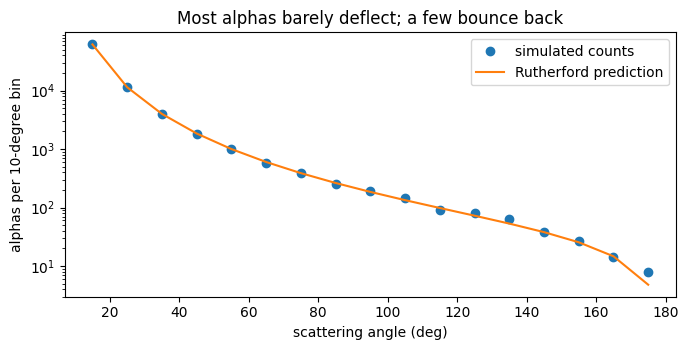

fraction scattered beyond 90 deg: 0.00066   (prediction: (1/2)^2 / 20^2 = 0.00063)


In [11]:
n_alpha, b_max = 1_000_000, 20.0                            # impact parameters in units of d
b_values = b_max * np.sqrt(rng.uniform(size=n_alpha))         # uniform over the disc's area
theta = np.degrees(2 * np.arctan(1 / (2 * b_values)))

edges = np.arange(10, 181, 10)
counts, _ = np.histogram(theta, bins=edges)
b_at = lambda angle: 0.5 / np.tan(np.radians(angle) / 2)       # invert b = (d/2) cot(theta/2)
predicted = n_alpha * (b_at(edges[:-1])**2 - b_at(edges[1:])**2) / b_max**2

centers = (edges[:-1] + edges[1:]) / 2
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogy(centers, counts, "o", label="simulated counts")
ax.semilogy(centers, predicted, "-", label="Rutherford prediction")
ax.set_xlabel("scattering angle (deg)"); ax.set_ylabel("alphas per 10-degree bin")
ax.set_title("Most alphas barely deflect; a few bounce back"); ax.legend()
plt.tight_layout(); plt.show()

back = np.mean(theta > 90)
print(f"fraction scattered beyond 90 deg: {back:.5f}   (prediction: (1/2)^2 / {b_max:.0f}^2 = {0.25 / b_max**2:.5f})")
assert np.all(np.abs(counts - predicted) < 5 * np.sqrt(predicted) + 5)

# 6 — Into the nucleus

The nucleus holds $Z$ protons (the **atomic number**, which fixes the
element) and $N$ neutrons; $A = Z + N$ is the **mass number**. Atoms of
one element with different $N$ are **isotopes**.

Scattering experiments show a nucleus's radius grows as
$R \approx (1.2\ \text{fm})\,A^{1/3}$. Volume is then proportional to
$A$, so every nucleus has roughly the **same density** — nuclear matter
is packed like marbles in a bag.

In [12]:
atomic_mass_unit = physical_constants["atomic mass constant"][0]
print(" nucleus     A    radius (fm)   density (kg/m^3)")
densities = []
for name, A in [("He-4", 4), ("C-12", 12), ("Fe-56", 56), ("Au-197", 197), ("U-238", 238)]:
    radius = 1.2e-15 * A ** (1 / 3)
    density = A * atomic_mass_unit / (4 / 3 * np.pi * radius**3)
    densities.append(density)
    print(f" {name:8s} {A:5d}    {radius * 1e15:6.2f}        {density:.2e}")
assert np.allclose(densities, densities[0])

# when does Rutherford's pure-Coulomb picture break? when the alpha touches the nucleus
touching_fm = 1.2 * (197 ** (1 / 3) + 4 ** (1 / 3))
K_touch = ke2_MeV_fm * 2 * Z_gold / touching_fm
print(f"\ngold + alpha radii = {touching_fm:.1f} fm; an alpha needs about {K_touch:.0f} MeV to touch the gold nucleus")
print(f"at 5 MeV it turns back at {d_fm:.0f} fm, so the scattering is purely electric -- as Rutherford assumed")
assert K_touch > 20

 nucleus     A    radius (fm)   density (kg/m^3)
 He-4         4      1.90        2.29e+17
 C-12        12      2.75        2.29e+17
 Fe-56       56      4.59        2.29e+17
 Au-197     197      6.98        2.29e+17
 U-238      238      7.44        2.29e+17

gold + alpha radii = 8.9 fm; an alpha needs about 26 MeV to touch the gold nucleus
at 5 MeV it turns back at 46 fm, so the scattering is purely electric -- as Rutherford assumed


A teaspoon of nuclear matter (5 mL) would have a mass of about a
billion tonnes: $2.3\times10^{17}\ \text{kg/m}^3 \times 5\times10^{-6}\ \text{m}^3
\approx 1\times10^{12}$ kg. Ordinary matter is almost entirely empty
space.

# 7 — Classical physics at the limit

Rutherford's atom raised a problem classical physics could not solve.
An electron circling a nucleus is accelerating, and Maxwell's equations
say an accelerating charge radiates (the **Larmor formula**):

$$P = \frac{2}{3}\frac{k e^2 a^2}{c^3}.$$

The radiated energy must come from the orbit, so the electron should
spiral inward. Combining $P$ with the orbital energy
$E = -ke^2/2r$ and $a = ke^2/(m r^2)$ gives a differential equation for
the radius. SymPy solves it below. The answer is written with the
**classical electron radius** $r_e = ke^2/(mc^2) = 2.82$ fm.

In [13]:
r_t, t_s, r0, re_s, c_s = sp.symbols("r t r_0 r_e c", positive=True)

# dr/dt = -P / (dE/dr) works out to  dr/dt = -(4/3) r_e^2 c / r^2
k_s, e_s, m_s2 = sp.symbols("k e m", positive=True)
r_sym = sp.Symbol("r", positive=True)
accel = k_s * e_s**2 / (m_s2 * r_sym**2)
P_larmor = sp.Rational(2, 3) * k_s * e_s**2 * accel**2 / c_s**3
dE_dr = sp.diff(-k_s * e_s**2 / (2 * r_sym), r_sym)
dr_dt = sp.simplify((-P_larmor / dE_dr).subs(k_s * e_s**2, re_s * m_s2 * c_s**2))
print("dr/dt =", dr_dt)
assert sp.simplify(dr_dt + sp.Rational(4, 3) * re_s**2 * c_s / r_sym**2) == 0

# separate and integrate from r0 down to 0
collapse_time = sp.solve(sp.Eq(sp.integrate(r_sym**2, (r_sym, r0, 0)),
                               sp.integrate(-sp.Rational(4, 3) * re_s**2 * c_s, (t_s, 0, sp.Symbol("T")))),
                         sp.Symbol("T"))[0]
print("collapse time T =", collapse_time)

a0 = physical_constants["Bohr radius"][0]
r_e = physical_constants["classical electron radius"][0]
T_numeric = float(collapse_time.subs({r0: a0, re_s: r_e, c_s: c}))
print(f"\nstarting at the size of a hydrogen atom ({a0 * 1e9:.4f} nm): T = {T_numeric:.2e} s")
assert abs(T_numeric - 1.56e-11) < 0.01e-11

dr/dt = -4*c*r_e**2/(3*r**2)
collapse time T = r_0**3/(4*c*r_e**2)

starting at the size of a hydrogen atom (0.0529 nm): T = 1.56e-11 s


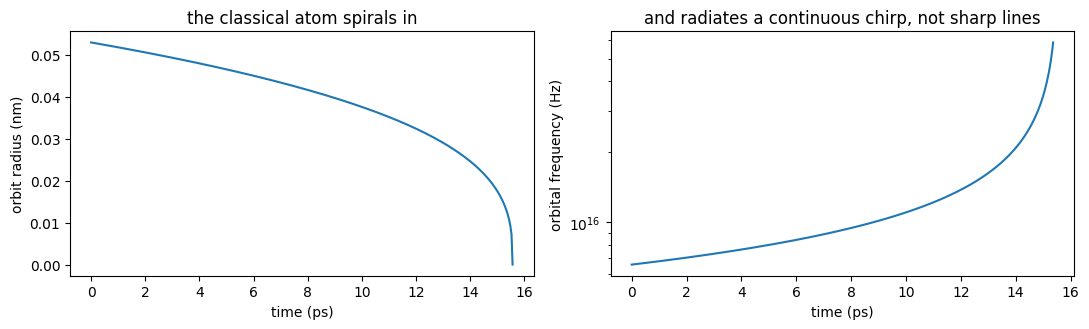

In [14]:
T_axis = np.linspace(0, T_numeric, 400)
radius_t = np.cbrt(a0**3 - 4 * r_e**2 * c * T_axis)            # from r^3 = r0^3 - 4 r_e^2 c t
orbit_freq = np.sqrt(k * e**2 / (m_e * np.maximum(radius_t, 1e-13)**3)) / (2 * np.pi)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(T_axis * 1e12, radius_t * 1e9)
axes[0].set_xlabel("time (ps)"); axes[0].set_ylabel("orbit radius (nm)")
axes[0].set_title("the classical atom spirals in")
axes[1].semilogy(T_axis[:-5] * 1e12, orbit_freq[:-5])
axes[1].set_xlabel("time (ps)"); axes[1].set_ylabel("orbital frequency (Hz)")
axes[1].set_title("and radiates a continuous chirp, not sharp lines")
plt.tight_layout(); plt.show()

Two predictions, both wrong:

1. **Atoms would not last.** Every atom would collapse in about
   16 picoseconds. Atoms are stable.
2. **Spectra would be continuous.** As the orbit shrinks its frequency
   rises smoothly, so the emitted light would sweep through all
   frequencies — a chirp. Real atoms emit the sharp lines of Section 1.

Classical physics had reached its limit. The next chapter's ideas —
quantized light and quantized energy levels — fix both problems at once.

# Practice problems

1. Electrons pass undeflected through $E = 1.5\times10^4$ V/m and
   $B = 0.60$ mT. How fast are they going?
2. X rays of 0.154 nm reflect from planes 0.282 nm apart. At what angle
   is the second-order reflection?
3. A 7.7 MeV alpha heads straight at a gold nucleus. How close does it get?
4. What is the shortest wavelength in hydrogen's Balmer series?

In [15]:
a1 = 1.5e4 / 0.60e-3
a2 = np.degrees(np.arcsin(2 * 0.154 / (2 * 0.282)))
a3 = ke2_MeV_fm * 2 * 79 / 7.7
a4 = 4 * lambda_0 * 1e9
print(f"1. v = E/B = {a1:.2e} m/s")
print(f"2. theta_2 = {a2:.1f} deg")
print(f"3. d = {a3:.1f} fm")
print(f"4. series limit (n -> infinity, m = 2) = {a4:.1f} nm")
assert abs(a1 - 2.5e7) < 1 and abs(a2 - 33.1) < 0.1 and abs(a3 - 29.5) < 0.1 and abs(a4 - 364.7) < 0.1

1. v = E/B = 2.50e+07 m/s
2. theta_2 = 33.1 deg
3. d = 29.5 fm
4. series limit (n -> infinity, m = 2) = 364.7 nm


# Summary sheet

| Experiment / idea | Equation | What it showed |
|---|---|---|
| Hydrogen spectrum | $\lambda = \dfrac{91.18\ \text{nm}}{1/m^2 - 1/n^2}$ | atoms emit only certain wavelengths |
| X-ray diffraction | $2d\sin\theta = m\lambda$ | X rays are short-wavelength waves; crystals are regular |
| Crossed fields | $v = E/B$ | a speed selector |
| Thomson | $\dfrac{q}{m} = \dfrac{2yE}{B^2L^2}$ | cathode rays are one kind of particle with large $e/m$ |
| Millikan | $r = \sqrt{\dfrac{9\eta v}{2\rho g}}$, $q = \dfrac{mgd}{V}$ | charge comes in whole multiples of $e$ |
| Rutherford | $d = \dfrac{k(2e)(Ze)}{K}$, $b = \dfrac{d}{2}\cot\dfrac{\theta}{2}$ | a tiny, dense, positive nucleus |
| Nuclear size | $R = 1.2\ \text{fm}\,A^{1/3}$ | nuclear density is the same for all nuclei |
| Classical collapse | $T = \dfrac{r_0^3}{4r_e^2c} \approx 1.6\times10^{-11}$ s | classical physics cannot explain stable atoms |

**What is simulated here.** The Millikan drops and the alpha
scattering counts are generated by the code, with stated noise, and
then analysed without access to the hidden values. The constants and
the closed-form results are real.